Training: (398, 30)
Validation: (85, 30)
Test: (86, 30)

Model Comparison:
           Model  Accuracy  Training Time (seconds)
0  Random Forest  0.883721                 0.957444
1        XGBoost  0.930233                 3.402786

XGBoost Best Iteration:
400

Random Forest Top 10 Features:
worst concave points    0.158955
worst area              0.146962
worst perimeter         0.085793
worst radius            0.078952
mean radius             0.077714
mean perimeter          0.074234
mean concave points     0.065869
mean concavity          0.054281
mean area               0.041657
worst concavity         0.031362
dtype: float64

XGBoost Top 10 Features:
worst perimeter         0.494872
worst radius            0.208322
worst concave points    0.050402
mean concave points     0.039990
worst compactness       0.038970
mean perimeter          0.028629
concavity error         0.026999
worst texture           0.012462
worst area              0.011702
worst concavity         0.010461
dtype: 

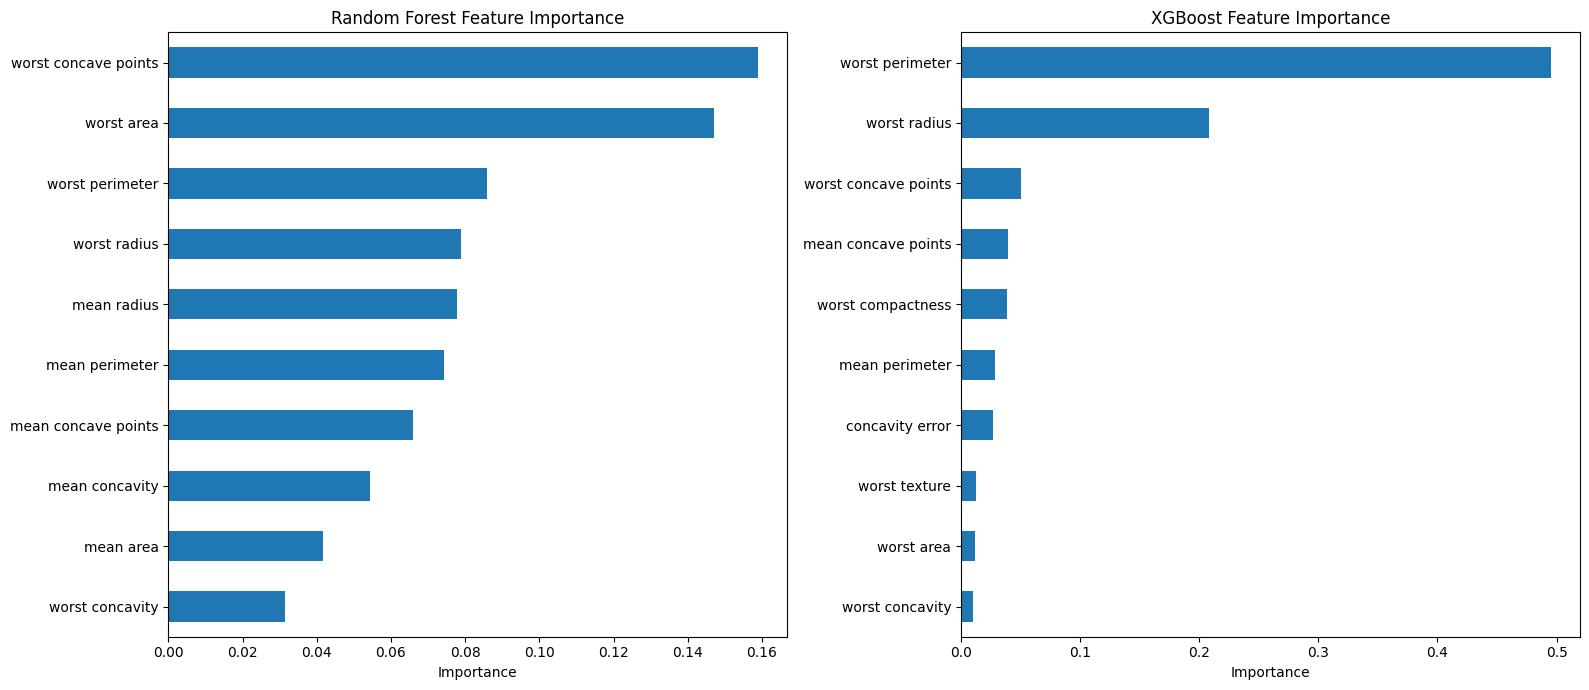

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


# ============================================================
# 1. LOAD DATASET
# ============================================================

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

feature_names = data.feature_names


# ============================================================
# 2. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split the 30% temporary data into:
# 15% validation + 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


# ============================================================
# 3. RANDOM FOREST
# ============================================================

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf.fit(X_train, y_train)

rf_training_time = time.time() - start_time

rf_predictions = rf.predict(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)


# ============================================================
# 4. XGBOOST
# ============================================================

xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    eval_metric="logloss",
    early_stopping_rounds=30
)

start_time = time.time()

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

xgb_training_time = time.time() - start_time

xgb_predictions = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(
    y_test,
    xgb_predictions
)


# ============================================================
# 5. COMPARE RESULTS
# ============================================================

results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [rf_accuracy, xgb_accuracy],
    "Training Time (seconds)": [
        rf_training_time,
        xgb_training_time
    ]
})

print("\nModel Comparison:")
print(results)


# ============================================================
# 6. XGBOOST BEST ITERATION
# ============================================================

print("\nXGBoost Best Iteration:")
print(xgb_model.best_iteration)


# ============================================================
# 7. FEATURE IMPORTANCE
# ============================================================

rf_importance = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)


# ============================================================
# 8. TOP 10 FEATURES
# ============================================================

rf_top10 = rf_importance.head(10)
xgb_top10 = xgb_importance.head(10)

print("\nRandom Forest Top 10 Features:")
print(rf_top10)

print("\nXGBoost Top 10 Features:")
print(xgb_top10)


# ============================================================
# 9. FEATURE IMPORTANCE SIDE-BY-SIDE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

# Random Forest
rf_top10.sort_values().plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title("Random Forest Feature Importance")
axes[0].set_xlabel("Importance")


# XGBoost
xgb_top10.sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("XGBoost Feature Importance")
axes[1].set_xlabel("Importance")


plt.tight_layout()
plt.show()

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("henriqueyamahata/bank-marketing")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'bank-marketing' dataset.
Path to dataset files: /kaggle/input/bank-marketing


In [3]:
import os
import kagglehub
import pandas as pd

# Let's resolve the actual dataset path
path = kagglehub.dataset_download("henriqueyamahata/bank-marketing")

# List all files inside the downloaded directory to find the correct file path
print("Files in dataset folder:")
files_list = []
for root, dirs, files in os.walk(path):
    for file in files:
        full_p = os.path.join(root, file)
        files_list.append(full_p)
        print("- ", os.path.relpath(full_p, path))

# Automatically find any CSV containing 'bank-full' or just a CSV
target_csv = None
for p in files_list:
    if p.endswith('.csv'):
        target_csv = p
        if 'bank-full' in p:
            break

if target_csv:
    print(f"\nLoading: {target_csv}")
    df = pd.read_csv(target_csv, sep=";")
    print(df.head())
    print(df.shape)
else:
    print("\nNo CSV file found in the dataset directory.")

Using Colab cache for faster access to the 'bank-marketing' dataset.
Files in dataset folder:
-  bank-additional-names.txt
-  bank-additional-full.csv

Loading: /kaggle/input/bank-marketing/bank-additional-full.csv
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   

In [4]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [6]:
print(X.shape)

(569, 30)


In [7]:
print(y.shape)

(569,)


In [8]:
X = df.drop('y', axis=1)
y = df['y']

In [9]:
print(X.shape)

(41188, 20)


In [10]:
categorical_features = X.select_dtypes(
    include = ["object"]
    ).columns
numerical_features = X.select_dtypes(
        exclude = ["object"]
    ).columns
print("categorical_features")
print(categorical_features)
print("\nnumerical_features")
print(numerical_features)

categorical_features
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object')

numerical_features
Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')


In [11]:
from sklearn.model_selection import train_test_split

# 1. Split into Train (70%) and Temporary (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 2. Split Temporary into Validation (15%) and Test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Training shape: (28831, 20)
Validation shape: (6178, 20)
Test shape: (6179, 20)


In [12]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [13]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)


In [14]:
from sklearn.ensemble import RandomForestClassifier
import time

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10,
    n_jobs=-1
)

start = time.time()
rf.fit(X_train_encoded, y_train)
rf_time = time.time() - start

# Fixed to use X_test_encoded instead of raw X_test
rf_accuracy = rf.score(
    X_test_encoded, y_test
)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Training Time: {rf_time:.4f} seconds")

Random Forest Accuracy: 0.9095
Training Time: 3.8447 seconds


In [15]:
y_train_xgb = y_train.map({
    "yes" : 0,
    "no" : 1
})
y_test_xgb = y_test.map({
    "yes" : 0,
    "no" : 1
})
y_val_xgb = y_val.map({
    "yes" : 0,
    "no" : 1
})

import xgboost as xgb
import time

# Fixed: 1. Changed n_estimator to n_estimators
#        2. Fixed variable name from xbg_model to xgb_model
#        3. Fixed eval_metric to use the string "logloss"
xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    random_state=42,
    max_depth=4,
    learning_rate=0.05,
    eval_metric="logloss",
    early_stopping_rounds=30
)

start = time.time()
# Fixed: Added eval_set with validation data so early stopping functions correctly
xgb_model.fit(
    X_train_encoded,
    y_train_xgb,
    eval_set=[(X_val_encoded, y_val_xgb)],
    verbose=False
)
xgb_time = time.time() - start

# Fixed: Calculate accuracy using correct encoded test features and mapped target
xgb_accuracy = xgb_model.score(X_test_encoded, y_test_xgb)

print("XGB Accuracy:", xgb_accuracy)
print("XGB Boost training time:", xgb_time)
print("Best iteration:", xgb_model.best_iteration)

XGB Accuracy: 0.918918918918919
XGB Boost training time: 2.9634454250335693
Best iteration: 469


In [16]:
print("\n===== MODEL COMPARISON =====")

print(
    f"Random Forest → "
    f"Accuracy: {rf_accuracy:.4f}, "
    f"Time: {rf_time:.2f}s"
)

print(
    f"XGBoost → "
    f"Accuracy: {xgb_accuracy:.4f}, "
    f"Time: {xgb_time:.2f}s"
)


===== MODEL COMPARISON =====
Random Forest → Accuracy: 0.9095, Time: 3.84s
XGBoost → Accuracy: 0.9189, Time: 2.96s


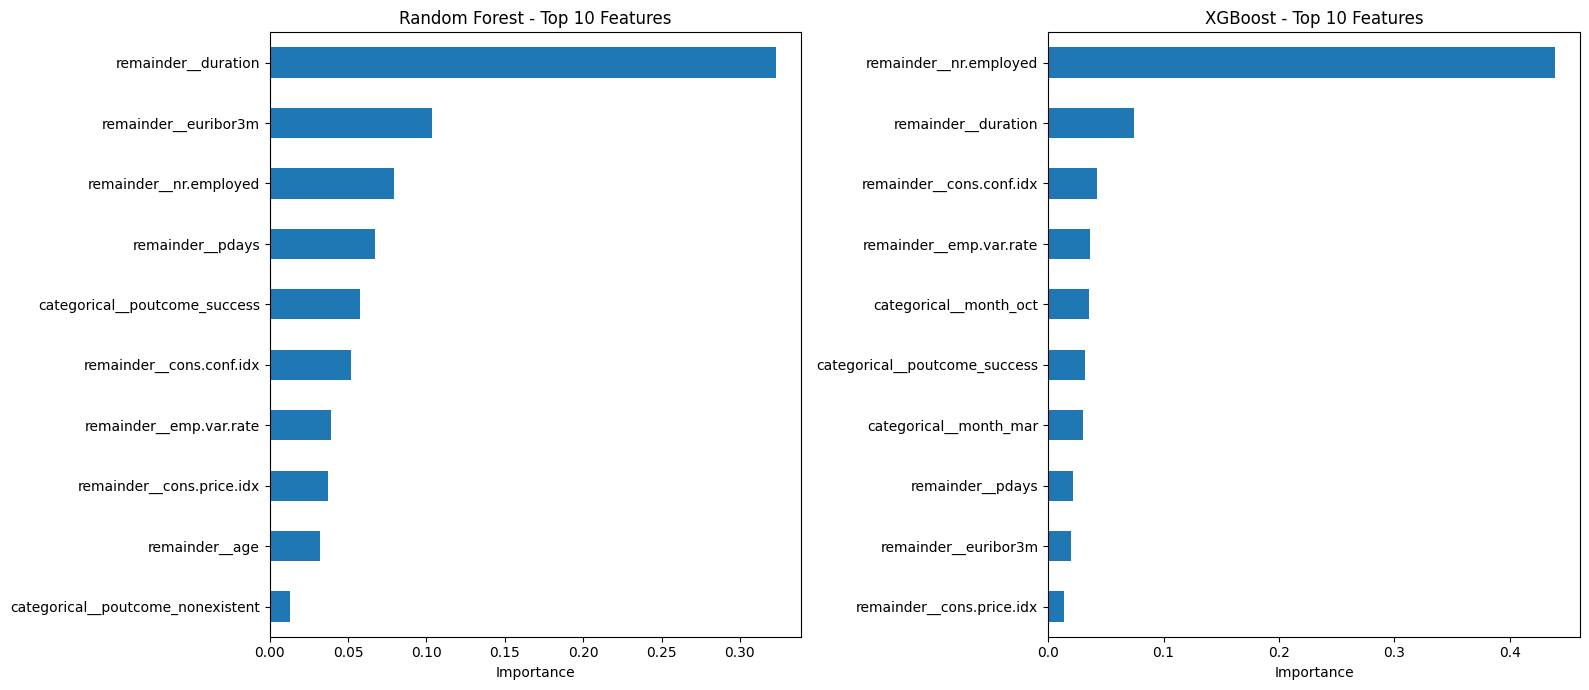

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Correctly call get_feature_names_out with parentheses
feature_names = preprocessor.get_feature_names_out()

# 2. Fix the attribute name (feature_importances_) and Series capitalization (pd.Series)
rf_importance = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

# 3. Calculate XGBoost feature importances using the trained xgb_model
xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

# 4. Plot top 10 features side-by-side
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

rf_importance.head(10).sort_values().plot(
    kind="barh",
    ax=axes[0]
)
axes[0].set_title("Random Forest - Top 10 Features")
axes[0].set_xlabel("Importance")

xgb_importance.head(10).sort_values().plot(
    kind="barh",
    ax=axes[1]
)
axes[1].set_title("XGBoost - Top 10 Features")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()

In [18]:
plt.tight_layout()

plt.savefig(
    "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>